<a href="https://colab.research.google.com/github/heejaejang/NCAA-Regression-Project/blob/main/NCAA_Next_Season_Forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NCAA Next-Season Scoring Forecast

**Research question:** once you know how a college basketball player performed this season, does his high-school recruiting ranking still help predict how he will perform next season?

**Why it matters:** coaches and scouts project next season's production for roster planning, transfers, and playing-time decisions. If recruiting pedigree adds information that the box score misses, it should be part of those projections; if it doesn't, last season's stats are enough.

**Design:** link NCAA Division I players from the 2022 season to the 2023 season by player ID, build forecasts of 2023 points per game from 2022 statistics, and compare nested models with and without recruiting rank. Models are judged on 5-fold cross-validated error against a naive "same as last season" baseline.

This is Part 2 of the project. Part 1 (`NCAA_Regression_Analysis.ipynb`) explains scoring within a single season.

**Author:** Jay Jang

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (6, 4)

SEED = 67
CLASS_LEVELS = ["So", "Jr", "Sr"]   # class in the forecast season; So is the baseline
REPO_URL = "https://raw.githubusercontent.com/heejaejang/NCAA-Regression-Project/main/"


def read_season(path: str, **kwargs) -> pd.DataFrame:
    # Read a local copy if it exists, otherwise the copy in the GitHub repo.
    return pd.read_csv(path if Path(path).exists() else REPO_URL + path, low_memory=False, **kwargs)


def make_formula(response: str, terms: list[str]) -> str:
    return f"{response} ~ " + " + ".join(terms)

# 1. Load both seasons

Both files come from Bart Torvik's player statistics. The 2023 export has no header row, but its first 66 columns are in the same order as the 2022 file, plus one extra column (birthdate), so the 2022 column names are reused. The two unnamed columns at the end of the 2022 file are a player-role label and an undocumented numeric field.

In [2]:
season_2022 = read_season("data/CollegeBasketballPlayers2022.csv")
season_2022 = season_2022.rename(columns={"Unnamed: 64": "role", "Unnamed: 65": "unknown_65"})

season_2023 = read_season("data/CollegeBasketballPlayers2023.csv", header=None)
season_2023.columns = list(season_2022.columns) + ["birthdate"]

print("2022:", season_2022.shape, "| 2023:", season_2023.shape)
print("Duplicate player IDs - 2022:", season_2022["pid"].duplicated().sum(),
      "| 2023:", season_2023["pid"].duplicated().sum())
season_2023[["player_name", "team", "yr", "GP", "mp", "pts", "pid"]].head()

2022: (3978, 66) | 2023: (5043, 67)
Duplicate player IDs - 2022: 0 | 2023: 0


,player_name,team,yr,GP,mp,pts,pid
0,Jailyn Ingram,Georgia,Sr,24,10.5000,3.3333,44344
1,Deandre Dishman,Middle Tennessee,Sr,31,27.1515,10.5455,45840
2,DeJuan Clayton,California,Sr,9,31.5556,9.2222,46161
3,Brevin Galloway,Clemson,Sr,32,29.1875,11.1562,46357
4,Michael Henn,Penn St.,Sr,29,8.6207,2.4483,46366


# 2. Who returns? (survivorship)

Only players who appear in both seasons can be used to build a forecast. Seniors graduate, some players turn pro, and others leave Division I, so the returners are not a random sample. This section shows who drops out.

,players,return_rate
yr,,
Jr,1087,0.724
So,1197,0.722
Sr,1694,0.371


,players,return_rate
pts_quartile,,
Q1 (lowest),949,0.524
Q2,955,0.613
Q3,939,0.624
Q4 (highest),946,0.562


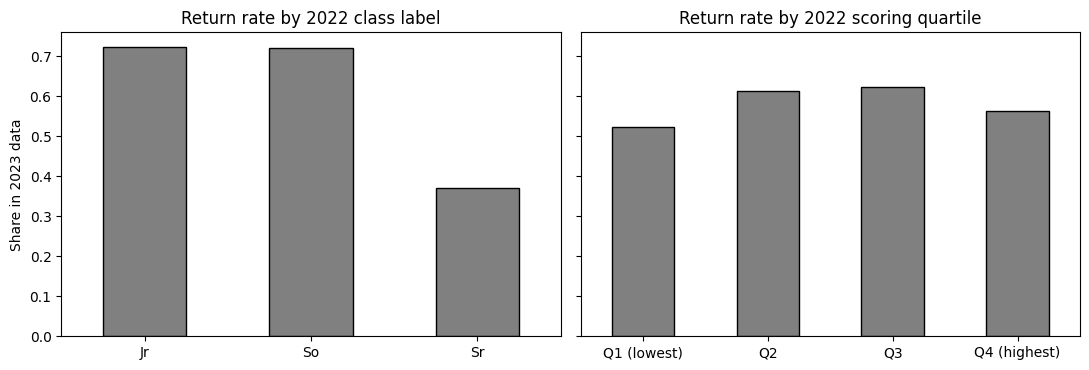

Overall: 2,280 of 3,978 players (57%) appear in 2023


In [3]:
season_2022["returns"] = season_2022["pid"].isin(season_2023["pid"])
season_2022["pts_quartile"] = pd.qcut(season_2022["pts"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

by_class = season_2022.groupby("yr")["returns"].agg(players="size", return_rate="mean")
by_scoring = season_2022.groupby("pts_quartile", observed=True)["returns"].agg(players="size", return_rate="mean")
display(by_class.round(3))
display(by_scoring.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
by_class["return_rate"].plot.bar(ax=axes[0], color="grey", edgecolor="black", rot=0)
axes[0].set(title="Return rate by 2022 class label", xlabel="", ylabel="Share in 2023 data")
by_scoring["return_rate"].plot.bar(ax=axes[1], color="grey", edgecolor="black", rot=0)
axes[1].set(title="Return rate by 2022 scoring quartile", xlabel="")
plt.tight_layout()
plt.show()

print(f"Overall: {season_2022['returns'].sum():,} of {len(season_2022):,} players "
      f"({season_2022['returns'].mean():.0%}) appear in 2023")

# 3. Link the seasons and build the analysis sample

Each 2022 player is matched to his 2023 record by player ID. Three data-quality decisions:

1. **Class labels.** The 2022 file contains no freshmen, and hundreds of linked players carry the same class label in both seasons (for example, 2022 "So" → 2023 "So"), which suggests that part of the 2022 labels are shifted up by one year. The model therefore uses the class a player is in **during the forecast season (2023)**, which is known before the season starts.
2. **Small samples.** Players with fewer than 5 games in either season are dropped, since per-game averages over 1–4 games are mostly noise.
3. **Recruiting rank** (0–100, higher = better recruit) exists only for ranked recruits. Being unranked is itself information, so unranked players are kept, with an `is_ranked` indicator and their rank set to 0.

A **transfer** is a player whose team changed between seasons. Transfer decisions are known before the season, so this is a legitimate predictor.

In [4]:
PREDICTOR_STATS = ["pts", "mp", "Min_per", "usg", "TS_per", "AST_per", "TO_per", "treb", "dbpm", "GP"]

prev = (season_2022[["pid", "player_name", "team", "yr", "Rec Rank", *PREDICTOR_STATS]]
        .rename(columns={c: f"{c}_prev" for c in ["team", "yr", *PREDICTOR_STATS]})
        .rename(columns={"Rec Rank": "rec_rank"}))
nxt = (season_2023[["pid", "team", "yr", "pts", "mp", "GP"]]
       .rename(columns={"team": "team_next", "yr": "class_next", "pts": "pts_next",
                        "mp": "mp_next", "GP": "GP_next"}))

linked = prev.merge(nxt, on="pid", how="inner", validate="one_to_one")
print(f"Linked players: {len(linked):,}")
print("\n2022 label (rows) vs 2023 label (columns):")
display(pd.crosstab(linked["yr_prev"], linked["class_next"]))

df = linked[(linked["GP_prev"] >= 5) & (linked["GP_next"] >= 5)
            & linked["class_next"].isin(CLASS_LEVELS)].copy()
df["class_next"] = pd.Categorical(df["class_next"], categories=CLASS_LEVELS)
df["transfer"] = (df["team_prev"] != df["team_next"]).astype(int)
df["is_ranked"] = df["rec_rank"].notna().astype(int)
df["rec_rank_filled"] = df["rec_rank"].fillna(0.0)
df["pts40_prev"] = df["pts_prev"] / df["mp_prev"] * 40
df["pts40_next"] = df["pts_next"] / df["mp_next"] * 40
df = df.dropna(subset=["pts_prev", "Min_per_prev", "usg_prev", "TS_per_prev", "AST_per_prev",
                       "TO_per_prev", "treb_prev", "dbpm_prev", "pts_next"]).reset_index(drop=True)

print(f"Analysis sample: {len(df):,} players | transfers: {df['transfer'].mean():.1%} "
      f"| ranked recruits: {df['is_ranked'].sum():,}")
print(f"Median games played - 2022: {df['GP_prev'].median():.0f}, 2023: {df['GP_next'].median():.0f}")

Linked players: 2,280

2022 label (rows) vs 2023 label (columns):


class_next,Fr,Jr,So,Sr
yr_prev,,,,
Jr,1,259,11,515
So,3,556,272,33
Sr,0,15,0,614


Analysis sample: 1,940 players | transfers: 32.9% | ranked recruits: 756
Median games played - 2022: 20, 2023: 30


# 4. How much does scoring carry over?

If scoring were perfectly stable, every point would sit on the dashed 45° line. The fitted line is flatter than 45°: players who scored a lot in 2022 tend to score somewhat less than that in 2023, and low scorers tend to score more. This is **regression to the mean**, and it is why simply copying last season's number is a poor forecast.

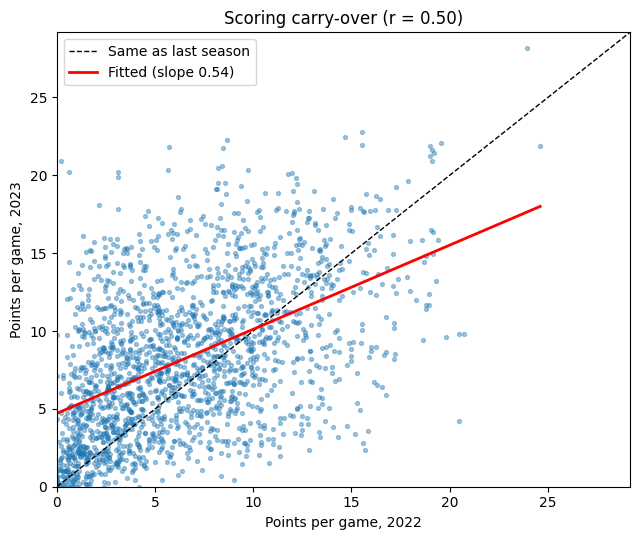

       pts_prev  pts_next
count   1940.00   1940.00
mean       6.45      8.20
std        4.47      4.84
min        0.00      0.00
25%        2.76      4.33
50%        5.68      7.78
75%        9.41     11.48
max       24.61     28.18


In [5]:
r = df[["pts_prev", "pts_next"]].corr().iloc[0, 1]
slope = np.polyfit(df["pts_prev"], df["pts_next"], 1)[0]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(df["pts_prev"], df["pts_next"], s=8, alpha=0.4)
lim = [0, max(df["pts_prev"].max(), df["pts_next"].max()) + 1]
ax.plot(lim, lim, "k--", linewidth=1, label="Same as last season")
sns.regplot(x="pts_prev", y="pts_next", data=df, scatter=False, ci=None, ax=ax,
            line_kws={"color": "red", "linewidth": 2}, label=f"Fitted (slope {slope:.2f})")
ax.set(xlim=lim, ylim=lim, xlabel="Points per game, 2022", ylabel="Points per game, 2023",
       title=f"Scoring carry-over (r = {r:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

print(df[["pts_prev", "pts_next"]].describe().round(2))

# 5. Does recruiting rank add information? (nested model test)

Two OLS models forecast 2023 scoring from 2022 statistics:

- **Base model:** last season's points, minutes %, usage, true shooting %, assist rate, turnover rate, rebounds, defensive BPM, class in the forecast season, and transfer status.
- **Recruiting model:** the base model plus `is_ranked` and `rec_rank_filled`.

The response is the **square root** of 2023 points per game. Part 1 found a Box-Cox λ of about 0.44 for points, close to a square root, and the square root also handles players who score 0 (Box-Cox requires positive values). A partial F test asks whether the two recruiting terms jointly improve the fit; HC3 robust standard errors guard against unequal error variance.

In [6]:
BASE_TERMS = ["pts_prev", "Min_per_prev", "usg_prev", "TS_per_prev", "AST_per_prev",
              "TO_per_prev", "treb_prev", "dbpm_prev", "class_next", "transfer"]
RECRUIT_TERMS = ["is_ranked", "rec_rank_filled"]

df["sqrt_pts_next"] = np.sqrt(df["pts_next"])
model_base = smf.ols(make_formula("sqrt_pts_next", BASE_TERMS), data=df).fit()
model_recruit = smf.ols(make_formula("sqrt_pts_next", BASE_TERMS + RECRUIT_TERMS), data=df).fit()
model_recruit_hc3 = smf.ols(make_formula("sqrt_pts_next", BASE_TERMS + RECRUIT_TERMS), data=df).fit(cov_type="HC3")

print("Partial F test: base vs base + recruiting")
print(anova_lm(model_base, model_recruit))
print(f"\nAdjusted R² - base: {model_base.rsquared_adj:.3f} | with recruiting: {model_recruit.rsquared_adj:.3f}")

pd.DataFrame({"coef": model_recruit.params, "HC3 SE": model_recruit_hc3.bse,
              "HC3 p": model_recruit_hc3.pvalues}).round(4)

Partial F test: base vs base + recruiting
   df_resid          ssr  df_diff    ss_diff          F    Pr(>F)
0    1928.0  1155.719358      0.0        NaN        NaN       NaN
1    1926.0  1142.762383      2.0  12.956975  10.918776  0.000019

Adjusted R² - base: 0.295 | with recruiting: 0.302


,coef,HC3 SE,HC3 p
Intercept,1.6734,0.1715,0.0000
class_next[T.Jr],-0.0009,0.0629,0.9880
class_next[T.Sr],-0.0042,0.0631,0.9467
pts_prev,0.0600,0.0113,0.0000
Min_per_prev,0.0050,0.0016,0.0018
usg_prev,0.0263,0.0069,0.0001
TS_per_prev,0.0025,0.0021,0.2216
AST_per_prev,0.0083,0.0031,0.0082
TO_per_prev,-0.0099,0.0028,0.0004
treb_prev,-0.0265,0.0145,0.0677


# 6. How big is the recruiting effect in points?

A coefficient on the square-root scale is hard to read, so this converts it to points per game. For a typical ranked recruit (median 2022 statistics among ranked players, no transfer, the most common class), the model predicts 2023 scoring across the range of recruiting ranks.

Typical ranked player: rank 25 -> 7.13 ppg | rank 75 -> 8.12 ppg | difference +0.99 ppg


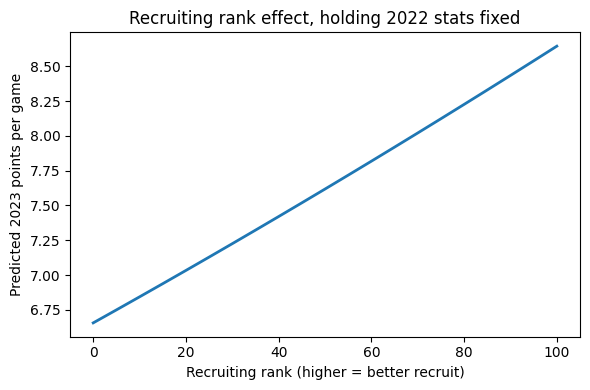

In [7]:
ranked = df[df["is_ranked"] == 1]
numeric_terms = [t for t in BASE_TERMS if t not in ("class_next", "transfer")]
typical = ranked[numeric_terms].median().to_dict()

grid = pd.DataFrame([{**typical, "class_next": ranked["class_next"].mode()[0], "transfer": 0,
                      "is_ranked": 1, "rec_rank_filled": rank} for rank in np.arange(0, 101, 5)])
grid["class_next"] = pd.Categorical(grid["class_next"], categories=CLASS_LEVELS)
grid["pred_pts"] = model_recruit.predict(grid).clip(lower=0) ** 2

low, high = grid.set_index("rec_rank_filled").loc[[25, 75], "pred_pts"]
print(f"Typical ranked player: rank 25 -> {low:.2f} ppg | rank 75 -> {high:.2f} ppg "
      f"| difference {high - low:+.2f} ppg")

fig, ax = plt.subplots()
ax.plot(grid["rec_rank_filled"], grid["pred_pts"], linewidth=2)
ax.set(xlabel="Recruiting rank (higher = better recruit)", ylabel="Predicted 2023 points per game",
       title="Recruiting rank effect, holding 2022 stats fixed")
plt.tight_layout()
plt.show()

# 7. Robustness: ranked players only

The `is_ranked` indicator compares ranked recruits with everyone else. A stricter test uses only the ranked players: within that group, does a higher rank still predict more scoring?

In [8]:
model_ranked_only = smf.ols(make_formula("sqrt_pts_next", BASE_TERMS + ["rec_rank_filled"]),
                            data=ranked).fit(cov_type="HC3")
print(f"Ranked players: n = {len(ranked):,}")
print(f"rec_rank coefficient: {model_ranked_only.params['rec_rank_filled']:.5f} "
      f"(HC3 SE {model_ranked_only.bse['rec_rank_filled']:.5f}, p = {model_ranked_only.pvalues['rec_rank_filled']:.4f})")

Ranked players: n = 756
rec_rank coefficient: 0.00373 (HC3 SE 0.00110, p = 0.0007)


# 8. Forecast accuracy: 5-fold cross-validation

Statistical significance is not the same as better forecasts. Each model is trained on 4/5 of the players and scored on the remaining 1/5, five times, in points per game:

| Model | Description |
|---|---|
| Naive | 2023 points = 2022 points |
| OLS base | Section 5 base model |
| OLS + recruiting | Section 5 recruiting model |
| Gradient boosting | `HistGradientBoostingRegressor` on the same predictors plus recruiting rank (missing ranks handled natively), to check for non-linear effects |

All models see the same folds, and square-root predictions are squared back to points.

In [9]:
def gb_features(d: pd.DataFrame, prior: str) -> pd.DataFrame:
    # Numeric feature matrix for gradient boosting; class is coded 0/1/2 and missing ranks stay NaN.
    X = d[[prior if t == "pts_prev" else t for t in BASE_TERMS if t != "class_next"]].copy()
    X["class_next"] = d["class_next"].cat.codes
    X["rec_rank"] = d["rec_rank"]
    return X


def make_gb() -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=30, random_state=SEED)


def cv_forecasts(data: pd.DataFrame, target: str = "pts_next", prior: str = "pts_prev",
                 n_splits: int = 5) -> pd.DataFrame:
    # Cross-validated RMSE / MAE / R² for the naive, OLS, and gradient-boosting forecasts.
    base = [prior if t == "pts_prev" else t for t in BASE_TERMS]
    scores = {}
    for tr_idx, te_idx in KFold(n_splits, shuffle=True, random_state=SEED).split(data):
        tr, te = data.iloc[tr_idx].copy(), data.iloc[te_idx]
        tr["sqrt_y"] = np.sqrt(tr[target])
        preds = {
            "Naive (same as last season)": te[prior],
            "OLS base": smf.ols(make_formula("sqrt_y", base), data=tr).fit().predict(te).clip(lower=0) ** 2,
            "OLS + recruiting": smf.ols(make_formula("sqrt_y", base + RECRUIT_TERMS), data=tr).fit()
                                   .predict(te).clip(lower=0) ** 2,
            "Gradient boosting": make_gb().fit(gb_features(tr, prior), tr[target]).predict(gb_features(te, prior)),
        }
        for name, p in preds.items():
            s = scores.setdefault(name, {"RMSE": [], "MAE": [], "R²": []})
            s["RMSE"].append(mean_squared_error(te[target], p) ** 0.5)
            s["MAE"].append(mean_absolute_error(te[target], p))
            s["R²"].append(r2_score(te[target], p))
    return pd.DataFrame({name: {"RMSE": np.mean(s["RMSE"]), "RMSE sd": np.std(s["RMSE"]),
                                "MAE": np.mean(s["MAE"]), "R²": np.mean(s["R²"])}
                         for name, s in scores.items()}).T.round(3)


cv_ppg = cv_forecasts(df)
cv_ppg

,RMSE,RMSE sd,MAE,R²
Naive (same as last season),4.980,0.123,3.808,-0.064
OLS base,4.177,0.136,3.320,0.251
OLS + recruiting,4.156,0.134,3.306,0.258
Gradient boosting,4.287,0.136,3.403,0.211


# 9. Separating role from efficiency: points per 40 minutes

Points per game mixes two things: how much a player plays (role) and how much he scores while on the floor (efficiency). Repeating the comparison with **points per 40 minutes** as the target asks whether recruiting rank predicts *efficiency*, not just a bigger role. Players averaging under 10 minutes in either season are excluded, since per-40 rates from very few minutes are unstable.

In [10]:
df_eff = df[(df["mp_prev"] >= 10) & (df["mp_next"] >= 10)].reset_index(drop=True)
print(f"Efficiency sample: {len(df_eff):,} players")
# Nested test on the efficiency scale: does recruiting rank predict scoring per minute?
df_eff["sqrt_pts40_next"] = np.sqrt(df_eff["pts40_next"])
base_eff = ["pts40_prev" if t == "pts_prev" else t for t in BASE_TERMS]
eff_base = smf.ols(make_formula("sqrt_pts40_next", base_eff), data=df_eff).fit()
eff_recruit = smf.ols(make_formula("sqrt_pts40_next", base_eff + RECRUIT_TERMS), data=df_eff).fit()
eff_recruit_hc3 = smf.ols(make_formula("sqrt_pts40_next", base_eff + RECRUIT_TERMS), data=df_eff).fit(cov_type="HC3")
print(anova_lm(eff_base, eff_recruit))
print(f"rec_rank coefficient: {eff_recruit_hc3.params['rec_rank_filled']:.5f} "
      f"(HC3 p = {eff_recruit_hc3.pvalues['rec_rank_filled']:.4f})")

cv_pts40 = cv_forecasts(df_eff, target="pts40_next", prior="pts40_prev")
cv_pts40

Efficiency sample: 1,393 players
   df_resid         ssr  df_diff  ss_diff         F    Pr(>F)
0    1381.0  331.323290      0.0      NaN       NaN       NaN
1    1379.0  330.003389      2.0   1.3199  2.757763  0.063783
rec_rank coefficient: 0.00094 (HC3 p = 0.2272)


,RMSE,RMSE sd,MAE,R²
Naive (same as last season),4.351,0.197,3.441,-0.074
OLS base,3.699,0.199,2.959,0.225
OLS + recruiting,3.695,0.200,2.951,0.227
Gradient boosting,4.016,0.146,3.210,0.086


# 10. What drives the gradient-boosting forecast?

Permutation importance measures how much the test-set error (RMSE) rises when one predictor's values are randomly shuffled. A larger rise means the model relies more on that predictor; values near zero (or below) mean it adds nothing.

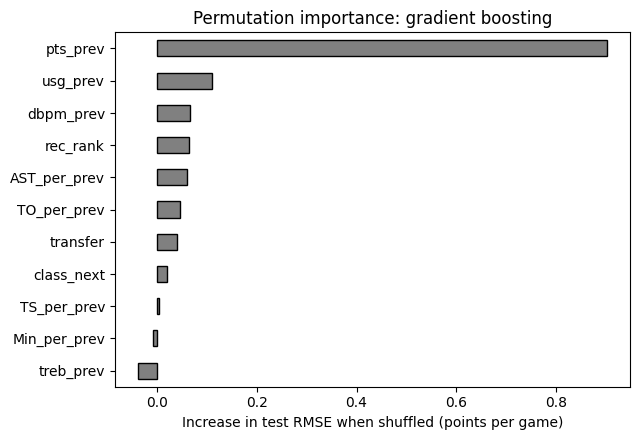

,RMSE increase (ppg)
pts_prev,0.901
usg_prev,0.110
dbpm_prev,0.066
rec_rank,0.064
AST_per_prev,0.061
TO_per_prev,0.047
transfer,0.040
class_next,0.021
TS_per_prev,0.004
Min_per_prev,-0.008


In [11]:
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
gb = make_gb().fit(gb_features(train, "pts_prev"), train["pts_next"])
perm = permutation_importance(gb, gb_features(test, "pts_prev"), test["pts_next"], n_repeats=20,
                              random_state=SEED, scoring="neg_root_mean_squared_error")

importance = (pd.Series(perm.importances_mean, index=gb_features(test, "pts_prev").columns,
                        name="RMSE increase (ppg)").sort_values())
fig, ax = plt.subplots(figsize=(6.5, 4.5))
importance.plot.barh(ax=ax, color="grey", edgecolor="black")
ax.set(xlabel="Increase in test RMSE when shuffled (points per game)",
       title="Permutation importance: gradient boosting")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(3)

# 11. Base-model diagnostics

Residual checks for the recruiting model on the square-root scale: residuals vs fitted values should show no pattern, and the Q-Q plot should be roughly straight.

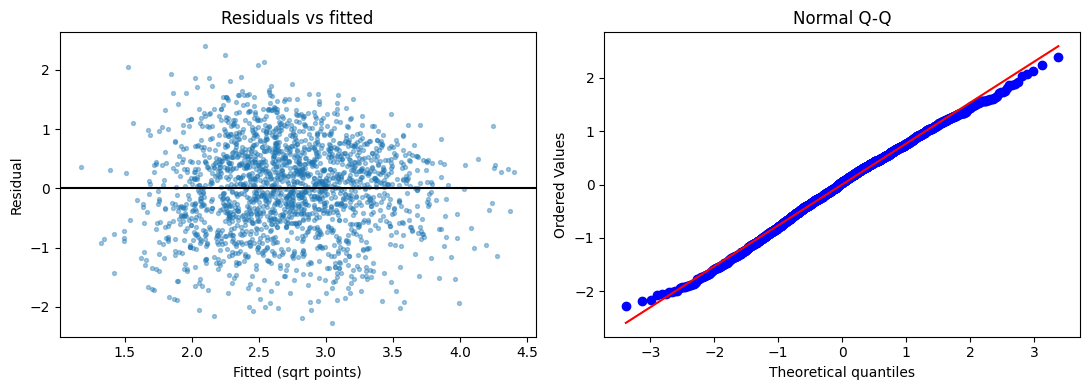

In [12]:
import scipy.stats as stats

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(model_recruit.fittedvalues, model_recruit.resid, s=8, alpha=0.4)
axes[0].axhline(0, color="black")
axes[0].set(xlabel="Fitted (sqrt points)", ylabel="Residual", title="Residuals vs fitted")
stats.probplot(model_recruit.resid, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q")
plt.tight_layout()
plt.show()

# 12. Results and limitations

**Answer to the research question: yes, recruiting rank adds information, but only a little, and mostly through playing time.**

**1. Scoring carries over only partly.** 2022 and 2023 points per game correlate at r = 0.50, and the fitted slope is 0.54: each extra point in 2022 predicts only about half a point more in 2023. Because of this regression to the mean, the naive "same as last season" forecast does worse than predicting the average (cross-validated R² = −0.06).

**2. Last season's stats give a much better forecast.** The base OLS model cuts cross-validated error from 4.98 to 4.18 points per game (16% lower) and explains about 25% of the variation in next-season scoring. Last season's points, usage, assist rate, turnover rate, and defensive BPM carry most of the signal; class year adds nothing once these are known.

**3. Recruiting rank is statistically real but small for forecasting.**

| Evidence | Result |
|---|---|
| Partial F test (all players) | F = 10.9, p = 0.00002 |
| Rank coefficient, ranked players only (HC3) | p = 0.0007 |
| Effect for a typical ranked player, rank 25 → 75 | about +1.0 points per game |
| Cross-validated RMSE, base → with recruiting | 4.18 → 4.16 points per game |

The effect is meaningful for an individual ranked recruit, but only 39% of players are ranked, so it barely moves overall forecast accuracy.

**4. Rank predicts role, not efficiency.** With points per 40 minutes as the target, recruiting rank is no longer significant (partial F p = 0.064; rank coefficient p = 0.23). Highly ranked recruits score more the next season mainly because they play bigger roles, not because they become more efficient scorers.

**5. Transfers score less than their stats predict** (p = 0.013 with HC3 standard errors), consistent with players adjusting to a new team and system.

**6. The simpler model wins.** Gradient boosting (RMSE 4.29) did worse than OLS (4.16). With about 1,900 players and a mostly linear signal, the extra flexibility mainly fits noise. Its permutation importance agrees with OLS: last season's points dominate, followed by usage, assist rate, and recruiting rank.

**Limitations**
- **One pair of seasons** (2022 → 2023); the results may not hold in other years.
- **Survivorship:** only 57% of 2022 players appear in 2023 (37% of seniors), so the forecasts apply to returning players only.
- **The 2022 file appears to be a mid-season snapshot** (median 20 games played vs 30 in 2023), so 2022 averages are noisier than full-season numbers.
- **Class labels** in the 2022 file are inconsistent with 2023; the model uses the forecast-season class instead.
- **Recruiting ranks** exist for only 756 of 1,940 players, and the transfer flag does not distinguish moves up or down in competition level.
- These are **associations, not causal effects**.